# 01 · Datos

**Pregunta.** ¿El conjunto de datos de entrenamiento es el de la sección 2.1 (cortes, filas,
prevalencia, variables), con las notas en sus dos representaciones, y está listo para entrenar?
¿Cuán redundantes son las candidatas entre sí?

**Regla de decisión** (plan, fase 1). Si algo no cuadra con la sección 2.1 (vacíos en las
variables del modelo, valores fuera de [0, 1], periodos o cortes que faltan), se para y se
pregunta a Jose. Este notebook no elige nada con la variable objetivo: solo describe.

Solo periodos de entrenamiento (2013B, 2013J, 2014B).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else "src")
import comun as c  # noqa: E402

import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from sklearn.decomposition import PCA  # noqa: E402

c.thesis_style()
pd.set_option("display.precision", 3)
data = {cut: c.load_train(cut) for cut in c.CUTS}

## 1. Filas, clases y prevalencia por corte y periodo

In [2]:
rows = []
for cut, d in data.items():
    for p, g in d.groupby("code_presentation"):
        rows.append({"corte": c.CUT_NAMES[cut], "periodo": p, "filas": len(g),
                     "asignaturas": g["code_module"].nunique(), "en riesgo (%)": 100 * g[c.TARGET].mean()})
    rows.append({"corte": c.CUT_NAMES[cut], "periodo": "Total", "filas": len(d),
                 "asignaturas": d["code_module"].nunique(), "en riesgo (%)": 100 * d[c.TARGET].mean()})
partition = pd.DataFrame(rows)
partition

,corte,periodo,filas,asignaturas,en riesgo (%)
0,Primer corte,2013B,3914,3,46.474
1,Primer corte,2013J,7401,6,39.535
2,Primer corte,2014B,6197,6,45.812
3,Primer corte,Total,17512,7,43.307
4,Segundo corte,2013B,3621,3,42.143
5,Segundo corte,2013J,6894,6,35.088
6,Segundo corte,2014B,5730,6,41.396
7,Segundo corte,Total,16245,7,38.886
8,Tercer corte,2013B,3425,3,38.832
9,Tercer corte,2013J,6581,6,32.001


In [3]:
modules = pd.crosstab(data["first"]["code_module"], data["first"]["code_presentation"])
modules

code_presentation,2013B,2013J,2014B
code_module,,,
AAA,0,360,0
BBB,1453,1780,1249
CCC,0,0,1392
DDD,1068,1552,954
EEE,0,885,572
FFF,1393,1905,1243
GGG,0,919,787


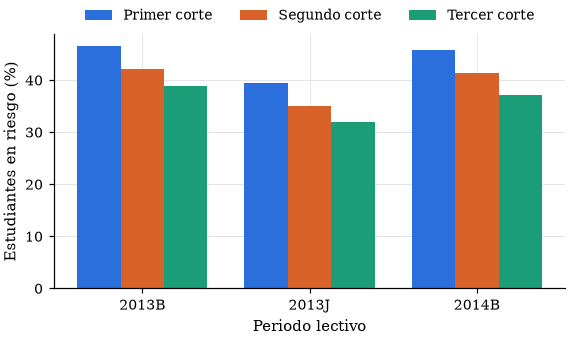

In [4]:
fig, ax = plt.subplots(figsize=(6, 3))
width = 0.26
for i, cut in enumerate(c.CUTS):
    prev = data[cut].groupby("code_presentation")[c.TARGET].mean() * 100
    x = np.arange(len(prev)) + (i - 1) * width
    ax.bar(x, prev.values, width, color=c.CUT_COLORS[cut], label=c.CUT_NAMES[cut])
ax.set_xticks(np.arange(len(c.TRAIN_PERIODS)), c.TRAIN_PERIODS)
ax.set_xlabel("Periodo lectivo")
ax.set_ylabel("Estudiantes en riesgo (%)")
ax.legend(ncols=3, loc="upper center", bbox_to_anchor=(0.5, 1.15))
c.save_figure(fig, "prevalencia_periodos")
plt.show()

## 2. Variables del modelo: vacíos y rangos

In [5]:
checks = []
for cut, d in data.items():
    X = d[c.features_for(cut)]
    checks.append({"corte": cut, "variables": X.shape[1], "vacíos": int(X.isna().sum().sum()),
                   "mínimo": X.min().min(), "máximo": X.max().max(),
                   "clases": d[c.CLASS].drop_duplicates().shape[0]})
pd.DataFrame(checks)

,corte,variables,vacíos,mínimo,máximo,clases
0,first,11,0,0.0,1.0,15
1,mid,13,0,0.0,1.0,15
2,last,13,0,0.0,1.0,15


## 3. Distribución de las variables según el resultado (segundo corte)

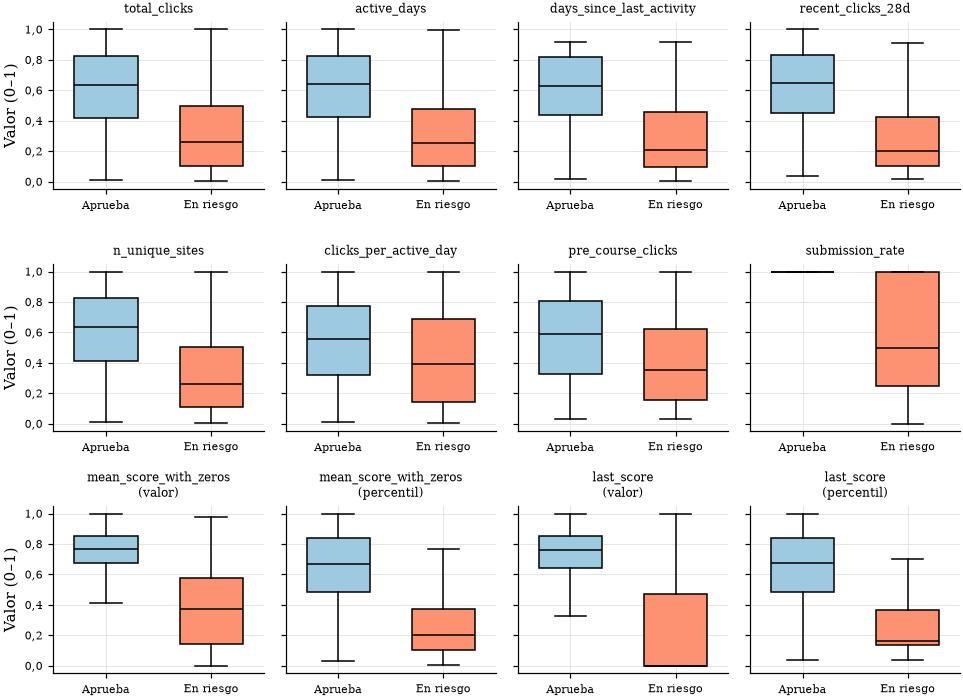

In [6]:
cut = "mid"
d = data[cut]
feats = c.VLE_PCT + ["submission_rate", "mean_score_with_zeros_raw", "mean_score_with_zeros_pct",
                     "last_score_raw", "last_score_pct"]
fig, axes = plt.subplots(3, 4, figsize=(9, 6.6), sharey=True)
for ax, f in zip(axes.flat, feats):
    vals = [d.loc[d[c.TARGET] == k, f] for k in (0, 1)]
    bp = ax.boxplot(vals, tick_labels=["Aprueba", "En riesgo"], widths=0.6, showfliers=False,
                    patch_artist=True, medianprops={"color": "black"})
    for patch, col in zip(bp["boxes"], ["#9ecae1", "#fc9272"]):
        patch.set_facecolor(col)
    ax.set_title(c.LABEL[f].replace(" (", "\n("), fontsize=8)
    ax.tick_params(labelsize=7)
    c.comma_axis(ax, "y", 1)
for ax in axes[:, 0]:
    ax.set_ylabel("Valor (0–1)")
fig.tight_layout()
c.save_figure(fig, "distribucion_variables_mid")
plt.show()

In [7]:
# repeated_course es binaria: proporción en riesgo según repita o no, por corte
pd.DataFrame({c.CUT_NAMES[cut]: data[cut].groupby("repeated_course")[c.TARGET].agg(["mean", "size"]).stack()
              for cut in c.CUTS})

Primer corte  Segundo corte  Tercer corte
repeated_course                                                
0               mean         0.410          0.364         0.328
                size     15236.000      14152.000     13390.000
1               mean         0.591          0.555         0.523
                size      2276.000       2093.000      1954.000

## 4. Correlaciones de Spearman entre las candidatas

Sin la variable objetivo. Interesan la redundancia entre las variables de VLE y la relación
entre las dos representaciones de cada nota.

In [8]:
corr = {cut: data[cut][c.features_for(cut)].corr(method="spearman") for cut in c.CUTS}
pairs = pd.DataFrame({cut: {
    "mean_score: valor vs percentil": corr[cut].loc["mean_score_with_zeros_raw", "mean_score_with_zeros_pct"],
    "last_score: valor vs percentil": corr[cut].loc["last_score_raw", "last_score_pct"] if cut != "first" else np.nan,
    "mean_score (valor) vs submission_rate": corr[cut].loc["mean_score_with_zeros_raw", "submission_rate"],
    "total_clicks vs active_days": corr[cut].loc["total_clicks_pct", "active_days_pct"],
    "total_clicks vs n_unique_sites": corr[cut].loc["total_clicks_pct", "n_unique_sites_pct"],
} for cut in c.CUTS})
pairs

,first,mid,last
mean_score: valor vs percentil,0.951,0.964,0.965
last_score: valor vs percentil,NaN,0.972,0.948
mean_score (valor) vs submission_rate,0.670,0.786,0.826
total_clicks vs active_days,0.903,0.922,0.930
total_clicks vs n_unique_sites,0.861,0.871,0.884


In [9]:
# Comprobación: dentro de cada clase el percentil es una transformación monótona del valor, así que
# su correlación de Spearman debe ser 1; las dos representaciones solo difieren entre clases.
within = {cut: data[cut].groupby(c.CLASS)[["mean_score_with_zeros_raw", "mean_score_with_zeros_pct"]]
          .corr(method="spearman").xs("mean_score_with_zeros_raw", level=-1)["mean_score_with_zeros_pct"]
          .describe()[["min", "50%", "max"]] for cut in c.CUTS}
pd.DataFrame(within)

,first,mid,last
min,1.0,1.0,1.0
50%,1.0,1.0,1.0
max,1.0,1.0,1.0


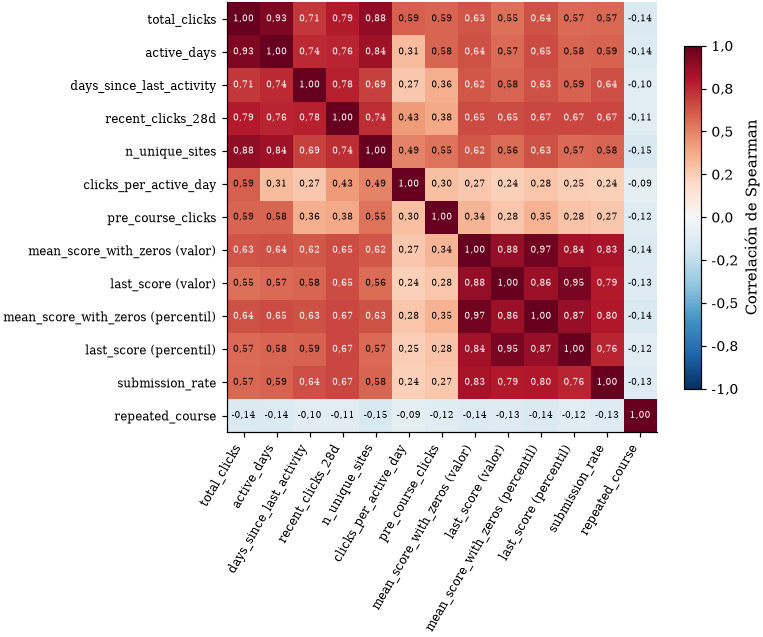

In [10]:
cm = corr["last"]
labels = [c.LABEL[f] for f in cm.columns]
fig, ax = plt.subplots(figsize=(6.3, 5.4))
im = ax.imshow(cm.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)), labels, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(labels)), labels, fontsize=8)
ax.grid(False)
for i in range(len(labels)):
    for j in range(len(labels)):
        v = cm.values[i, j]
        ax.text(j, i, c.comma(v, 2), ha="center", va="center", fontsize=6,
                color="white" if abs(v) > 0.6 else "black")
cb = fig.colorbar(im, ax=ax, shrink=0.75, label="Correlación de Spearman")
cb.ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: c.comma(x, 1)))
c.save_figure(fig, "correlaciones_last")
plt.show()

## 5. PCA de las variables de VLE (solo ilustración)

No se usa para elegir variables: muestra cuánta varianza comparten las siete de actividad.

In [11]:
pca_rows = {}
for cut in c.CUTS:
    ratio = PCA().fit(data[cut][c.VLE_PCT]).explained_variance_ratio_
    pca_rows[cut] = {"PC1 (%)": 100 * ratio[0], "PC1+PC2 (%)": 100 * ratio[:2].sum(),
                     "componentes para 90 %": int(np.searchsorted(np.cumsum(ratio), 0.9) + 1)}
pd.DataFrame(pca_rows)

,first,mid,last
PC1 (%),68.818,68.908,68.207
PC1+PC2 (%),80.714,80.933,80.253
componentes para 90 %,3.000,3.000,3.000


In [12]:
c.save_json({"partition": partition.to_dict("records"), "pairs": pairs.to_dict(),
             "pca": pca_rows}, c.ARTIFACTS / "01_datos.json")

## Conclusiones

- **Los datos cuadran con la sección 2.1.** 17 512 · 16 245 · 15 344 filas en los tres cortes,
  15 clases por corte (3 asignaturas en 2013B, 6 en 2013J y 2014B), sin vacíos y todas las
  variables del modelo en [0, 1]. No hay nada que preguntar a Jose.
- **Prevalencia** del 32 % al 46 %: baja de un corte al siguiente (abandonos ya excluidos) y
  varía entre periodos (2013J, unos 6 puntos por debajo). Desbalance moderado: se mantiene D7.
- **Todas las candidatas separan las dos clases**; las de evaluación con más claridad.
  `clicks_per_active_day` es la que menos. Repetir la asignatura eleva el riesgo del 41 % al 59 %
  en el primer corte.
- **Redundancia.** Las dos representaciones de cada nota tienen Spearman de 0,95–0,97: dentro
  de una clase ordenan igual (por construcción) y solo difieren entre clases. Las de VLE
  comparten mucho: el primer componente principal explica el 69 % de su varianza y tres
  explican el 90 %. Por eso la importancia por permutación se repartirá entre variables
  correlacionadas (D10) y la L1 tenderá a quedarse con una de cada grupo.
- Decisión: **E1** (datos aptos; se pasa a la fase 2 sin cambios).